# 01 · Datos: verificación, depuración y auditoría de calidad

**Rúbrica G:** fuentes de información, gestión y depuración de datos, control de calidad, criterios de inclusión y exclusión.

Pasos:
1. Cargar la base **oficial** UCI Cleveland y verificar su integridad con SHA-256.
2. Depurar: tipos de datos, desenlace binario `ec` y variable derivada `restecg_anormal`.
3. Controlar la calidad: rangos fisiológicos, códigos válidos, duplicados y faltantes.
4. Auditar la versión de Kaggle usada en el semestre 1, emparejando los registros con la base oficial.
5. Generar el diagrama de flujo de la muestra y el diccionario de variables.

In [1]:
%run ./00_configuracion.ipynb

## 1. Funciones de carga, depuración y auditoría

In [2]:
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def load_uci():
    """Carga la base oficial UCI Cleveland y verifica su integridad (SHA-256)."""
    digest = sha256(UCI_FILE)
    if digest != UCI_SHA256:
        raise ValueError(f"El archivo crudo cambió: SHA-256 {digest} != {UCI_SHA256}")
    df = pd.read_csv(UCI_FILE, names=UCI_COLUMNS, na_values="?")
    df.insert(0, "id", np.arange(1, len(df) + 1))
    return df


def clean(df):
    """Reglas de depuración documentadas en docs/plan_analisis.md §4."""
    out = df.copy()
    for col in ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "slope"]:
        out[col] = out[col].astype(int)
    out["ca"] = out["ca"].astype("Int64")
    out["thal"] = out["thal"].astype("Int64")
    # Desenlace: num 0 = < 50 % de estenosis; 1-4 = > 50 % en al menos un vaso
    out["ec"] = (out["num"] > 0).astype(int)
    out["restecg_anormal"] = (out["restecg"] > 0).astype(int)
    out["completo"] = out[["ca", "thal"]].notna().all(axis=1)
    return out


def range_checks(df):
    """Control de calidad: valores fuera de rangos fisiológicos o de codificación."""
    rules = {
        "age": (18, 100), "trestbps": (70, 250), "chol": (100, 700),
        "thalach": (50, 220), "oldpeak": (0, 10),
    }
    out = {}
    for col, (lo, hi) in rules.items():
        out[col] = int(((df[col] < lo) | (df[col] > hi)).sum())
    for col, meta in VARIABLES.items():
        if "categorias" in meta and col in df and col != "ec":
            valid = set(meta["categorias"])
            vals = set(df[col].dropna().astype(int).unique())
            out[f"{col}_codigos_invalidos"] = sorted(vals - valid)
    out["ca_fuera_0_3"] = int((df["ca"].dropna() > 3).sum())
    return out


def audit_kaggle(uci):
    """Compara la versión de Kaggle (usada en el semestre 1) con la oficial.

    Empareja registros por las variables continuas y binarias, que no cambian
    de codificación, y deriva empíricamente el mapeo de cada variable recodificada.
    """
    k = pd.read_csv(KAGGLE_FILE)
    key = ["age", "sex", "trestbps", "chol", "fbs", "thalach", "oldpeak"]
    u = uci.copy()
    m = k.reset_index().merge(u, on=key, suffixes=("_k", "_u"))
    mapping = {}
    for v in ["cp", "restecg", "slope", "ca", "thal"]:
        ct = pd.crosstab(m[f"{v}_k"], m[f"{v}_u"].astype("float").fillna(-1))
        mapping[v] = {int(kv): (None if ct.loc[kv].idxmax() == -1 else int(ct.loc[kv].idxmax()))
                      for kv in ct.index}
    tgt = pd.crosstab(m["target"], m["ec"])
    mapping["target"] = {int(kv): int(tgt.loc[kv].idxmax()) for kv in tgt.index}
    concord_target = float((m["target"] == m["ec"]).mean())
    dup = k.duplicated().sum()
    return {
        "n_kaggle": int(len(k)),
        "n_emparejados": int(len(m)),
        "registros_uci_unicos_emparejados": int(m["id"].nunique()),
        "duplicados_kaggle": int(dup),
        "mapeo_kaggle_a_uci": mapping,
        "concordancia_target_kaggle_vs_ec_uci": concord_target,
        "target_invertido": concord_target == 0.0,
        "faltantes_ocultos_kaggle": {"ca==4": int((k["ca"] == 4).sum()),
                                     "thal==0": int((k["thal"] == 0).sum())},
        "media_thalach_por_target_kaggle": k.groupby("target")["thalach"].mean().round(1).to_dict(),
        "media_thalach_por_ec_uci": uci.groupby("ec")["thalach"].mean().round(1).to_dict(),
    }, k


def build():
    raw = load_uci()
    df = clean(raw)
    audit = {
        "fuente": "UCI Machine Learning Repository, Heart Disease (Cleveland), DOI 10.24432/C52P4X",
        "sha256": UCI_SHA256,
        "n_total": int(len(df)),
        "n_variables": len(UCI_COLUMNS),
        "faltantes": {c: int(v) for c, v in df[UCI_COLUMNS].isna().sum().items() if v},
        "ids_con_faltantes": df.loc[~df["completo"], "id"].tolist(),
        "n_completos": int(df["completo"].sum()),
        "duplicados": int(df[UCI_COLUMNS].duplicated().sum()),
        "distribucion_num": df["num"].value_counts().sort_index().to_dict(),
        "eventos_ec": int(df["ec"].sum()),
        "prevalencia_ec": float(df["ec"].mean()),
        "control_rangos": range_checks(df),
    }
    kaggle_audit, kaggle = audit_kaggle(df)
    audit["auditoria_kaggle"] = kaggle_audit
    DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
    df.to_csv(DATA_PROCESSED / "cleveland_depurada.csv", index=False)
    return df, kaggle, audit

## 2. Ejecución

In [3]:
df, kaggle, audit = build()
cc = df[df.completo].copy()
cc["ca"] = cc["ca"].astype(int); cc["thal"] = cc["thal"].astype(int)
audit["eventos_cc"] = int(cc.ec.sum())
print(f"Registros: {audit['n_total']} | faltantes: {audit['faltantes']} | casos completos: {audit['n_completos']} "
      f"| eventos: {audit['eventos_cc']} ({100 * cc.ec.mean():.1f} %) | duplicados: {audit['duplicados']}")
print("Control de rangos y códigos:", audit["control_rangos"])
display(df.head())

Registros: 303 | faltantes: {'ca': 4, 'thal': 2} | casos completos: 297 | eventos: 137 (46.1 %) | duplicados: 0
Control de rangos y códigos: {'age': 0, 'trestbps': 0, 'chol': 0, 'thalach': 0, 'oldpeak': 0, 'sex_codigos_invalidos': [], 'cp_codigos_invalidos': [], 'fbs_codigos_invalidos': [], 'restecg_codigos_invalidos': [], 'restecg_anormal_codigos_invalidos': [], 'exang_codigos_invalidos': [], 'slope_codigos_invalidos': [], 'thal_codigos_invalidos': [], 'ca_fuera_0_3': 0}


,id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,ec,restecg_anormal,completo
0,1,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0,0,1,True
1,2,67,1,4,160,286,0,2,108,1,1.5,2,3,3,2,1,1,True
2,3,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1,1,1,True
3,4,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0,0,0,True
4,5,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0,0,1,True


## 3. Auditoría de la versión Kaggle

Las 303 filas de Kaggle se emparejan con UCI por las variables cuya codificación no cambia. La tabla cruzada de `target`
(Kaggle) contra `ec` (UCI) muestra si la etiqueta coincide.

In [4]:
ak = audit["auditoria_kaggle"]
print("Concordancia target (Kaggle) vs ec (UCI):", ak["concordancia_target_kaggle_vs_ec_uci"])
print("¿target invertido?:", ak["target_invertido"])
print("Mapeo Kaggle -> UCI:", json.dumps(ak["mapeo_kaggle_a_uci"], ensure_ascii=False))
print("Faltantes ocultos en Kaggle:", ak["faltantes_ocultos_kaggle"], "| duplicados en Kaggle:", ak["duplicados_kaggle"])
print("FC máxima media por target (Kaggle):", ak["media_thalach_por_target_kaggle"])
print("FC máxima media por ec (UCI):", ak["media_thalach_por_ec_uci"])

Concordancia target (Kaggle) vs ec (UCI): 0.0
¿target invertido?: True
Mapeo Kaggle -> UCI: {"cp": {"0": 4, "1": 2, "2": 3, "3": 1}, "restecg": {"0": 2, "1": 0, "2": 1}, "slope": {"0": 3, "1": 2, "2": 1}, "ca": {"0": 0, "1": 1, "2": 2, "3": 3, "4": null}, "thal": {"0": null, "1": 6, "2": 3, "3": 7}, "target": {"0": 1, "1": 0}}
Faltantes ocultos en Kaggle: {'ca==4': 5, 'thal==0': 2} | duplicados en Kaggle: 1
FC máxima media por target (Kaggle): {0: 139.1, 1: 158.5}
FC máxima media por ec (UCI): {0: 158.4, 1: 139.3}


**Interpretación.** La concordancia es 0: `target = 1` en Kaggle corresponde a pacientes **sin** enfermedad en UCI. Por eso,
en el semestre 1 la frecuencia cardíaca máxima pareció un factor de riesgo cuando en realidad es protectora. Además, `ca = 4`
y `thal = 0` son faltantes disfrazados de valores válidos, y hay un registro duplicado. **Desde aquí solo se usa la base oficial.**

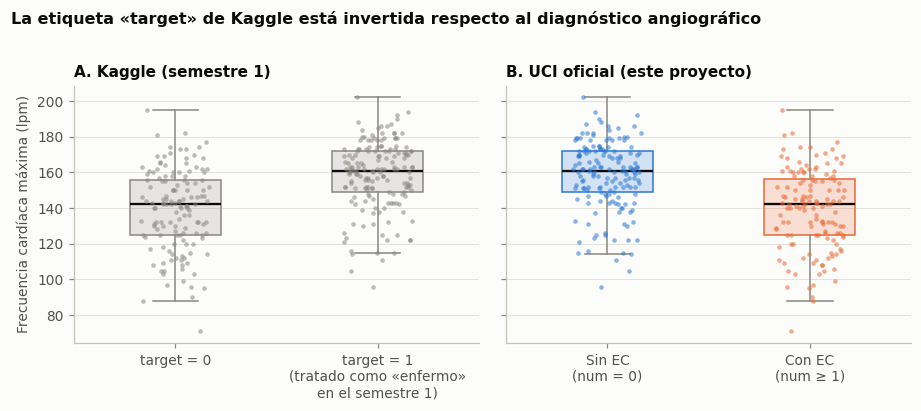

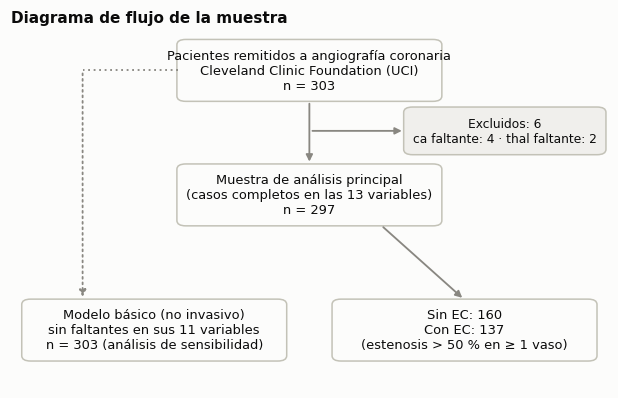

In [5]:
def fig_auditoria(kaggle, uci):
    setup(); rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.6), sharey=True)
    _box_strip(axes[0], [kaggle.loc[kaggle.target == 0, "thalach"], kaggle.loc[kaggle.target == 1, "thalach"]],
               [K["muted"], K["muted"]], ["target = 0", "target = 1\n(tratado como «enfermo»\nen el semestre 1)"], rng)
    axes[0].set_title("A. Kaggle (semestre 1)")
    axes[0].set_ylabel("Frecuencia cardíaca máxima (lpm)")
    _box_strip(axes[1], [uci.loc[uci.ec == 0, "thalach"], uci.loc[uci.ec == 1, "thalach"]],
               GROUP_COLORS, ["Sin EC\n(num = 0)", "Con EC\n(num ≥ 1)"], rng)
    axes[1].set_title("B. UCI oficial (este proyecto)")
    fig.suptitle("La etiqueta «target» de Kaggle está invertida respecto al diagnóstico angiográfico",
                 x=0.01, ha="left", fontsize=10.5, fontweight="bold", y=1.02)
    fig.tight_layout()
    save(fig, "fig01_auditoria_kaggle_vs_uci")


def fig_flujo(audit):
    setup()
    fig, ax = plt.subplots(figsize=(7, 4.2)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 10)
    falt = audit["faltantes"]
    boxes = [
        (5, 8.9, f"Pacientes remitidos a angiografía coronaria\nCleveland Clinic Foundation (UCI)\nn = {audit['n_total']}"),
        (5, 5.4, f"Muestra de análisis principal\n(casos completos en las 13 variables)\nn = {audit['n_completos']}"),
        (2.4, 1.6, f"Modelo básico (no invasivo)\nsin faltantes en sus 11 variables\nn = {audit['n_total']} (análisis de sensibilidad)"),
        (7.6, 1.6, f"Sin EC: {audit['n_completos'] - audit['eventos_cc']}\nCon EC: {audit['eventos_cc']}\n(estenosis > 50 % en ≥ 1 vaso)"),
    ]
    for x, y, t in boxes:
        ax.add_patch(FancyBboxPatch((x - 2.2, y - 0.85), 4.4, 1.7, boxstyle="round,pad=0.02,rounding_size=0.15",
                                    fc=K["surface"], ec=K["axis"], lw=1))
        ax.text(x, y, t, ha="center", va="center", fontsize=8.5)
    ax.add_patch(FancyBboxPatch((6.6, 6.55), 3.35, 1.3, boxstyle="round,pad=0.02,rounding_size=0.15",
                                fc="#f0efec", ec=K["axis"], lw=1))
    ax.text(8.27, 7.2, f"Excluidos: {audit['n_total'] - audit['n_completos']}\n"
                       f"ca faltante: {falt.get('ca', 0)} · thal faltante: {falt.get('thal', 0)}",
            ha="center", va="center", fontsize=8)
    arrow = dict(arrowstyle="-|>", color=K["muted"], lw=1.2)
    ax.annotate("", (5, 6.25), (5, 8.05), arrowprops=arrow)
    ax.annotate("", (6.6, 7.2), (5, 7.2), arrowprops=dict(arrowstyle="-|>", color=K["muted"], lw=1.2))
    ax.annotate("", (7.6, 2.45), (6.2, 4.55), arrowprops=arrow)
    # El análisis de sensibilidad parte de la población completa (n = 303), no de la muestra de casos completos
    dotted = dict(color=K["muted"], lw=1.2, linestyle=(0, (1, 2)))
    ax.plot([2.8, 1.2], [8.9, 8.9], **dotted)
    ax.annotate("", (1.2, 2.45), (1.2, 8.9), arrowprops=dict(arrowstyle="-|>", **dotted))
    ax.set_title("Diagrama de flujo de la muestra")
    save(fig, "fig02_flujo_muestra")


fig_auditoria(kaggle, df)
fig_flujo(audit)

## 4. Diccionario de variables (anexo del protocolo)

In [6]:
def write_dictionary(df):
    """docs/diccionario_variables.md generado desde config.VARIABLES (fuente única)."""
    lines = ["# Diccionario de variables", "",
             "> Archivo generado automáticamente por `notebooks/01_datos_y_auditoria.ipynb` desde `notebooks/00_configuracion.ipynb`. "
             "No editar a mano.", "",
             "Fuente: UCI Heart Disease, subconjunto Cleveland (`processed.cleveland.data`), "
             "codificación oficial según `data/raw/heart-disease.names`.", "",
             "| Variable | Nombre | Definición conceptual | Definición operacional | Unidad | Tipo | Escala | Rol | Grupo | Categorías / rango observado | Faltantes |",
             "|---|---|---|---|---|---|---|---|---|---|---|"]
    raw = load_uci()
    for v, m in VARIABLES.items():
        if "categorias" in m:
            rango = "; ".join(f"{k} = {lab}" for k, lab in m["categorias"].items())
        else:
            rango = f"{df[v].min():g} – {df[v].max():g}"
        falt = int(raw[v].isna().sum()) if v in raw else 0
        conc, oper = DEFINICIONES[v]
        lines.append(f"| `{v}` | {m['etiqueta']} | {conc} | {oper} | {m['unidad']} | {m['tipo']} | {m['escala']} | "
                     f"{m['rol']} | {m['grupo']} | {rango} | {falt} |")
    lines += ["", "Notas:", "",
              "- `ec` se deriva de `num` (0 = estenosis < 50 %; 1–4 = estenosis > 50 % en al menos un vaso mayor).",
              "- `restecg_anormal` agrupa anomalía ST-T (n = 4) e hipertrofia ventricular izquierda para "
              "estabilizar la estimación en los modelos; la Tabla 1 conserva las tres categorías.",
              "- Categorías de referencia en los OR: " + ", ".join(
                  f"`{k}` = {VARIABLES[k]['categorias'][r]}" for k, r in REFERENCE.items()) + ".",
              "- OR de continuas expresados por: " + ", ".join(
                  f"`{k}` {u} {VARIABLES[k]['unidad']}" for k, u in OR_UNITS.items()) + "."]
    (ROOT / "docs" / "diccionario_variables.md").write_text("\n".join(lines) + "\n", encoding="utf-8")


write_dictionary(cc)
display(Markdown((ROOT / 'docs' / 'diccionario_variables.md').read_text(encoding='utf-8')))

# Diccionario de variables

> Archivo generado automáticamente por `notebooks/01_datos_y_auditoria.ipynb` desde `notebooks/00_configuracion.ipynb`. No editar a mano.

Fuente: UCI Heart Disease, subconjunto Cleveland (`processed.cleveland.data`), codificación oficial según `data/raw/heart-disease.names`.

| Variable | Nombre | Definición conceptual | Definición operacional | Unidad | Tipo | Escala | Rol | Grupo | Categorías / rango observado | Faltantes |
|---|---|---|---|---|---|---|---|---|---|---|
| `age` | Edad | Tiempo de vida del paciente. | Años cumplidos al momento del estudio. | años | cuantitativa continua | razón | independiente | clínica | 29 – 77 | 0 |
| `sex` | Sexo masculino | Sexo biológico. | 1 = hombre, 0 = mujer, según el registro clínico. |  | cualitativa dicotómica | nominal | independiente | clínica | 0 = Mujer; 1 = Hombre | 0 |
| `cp` | Tipo de dolor torácico | Caracterización clínica del dolor torácico según su relación con el esfuerzo y su respuesta a nitratos. | Clasificación del médico tratante: típica (cumple 3 criterios), atípica (2), no anginoso (≤ 1), asintomático. |  | cualitativa politómica | nominal | independiente | clínica | 1 = Angina típica; 2 = Angina atípica; 3 = Dolor no anginoso; 4 = Asintomático | 0 |
| `trestbps` | Presión arterial sistólica en reposo | Presión que ejerce la sangre sobre las arterias durante la sístole, en reposo. | Presión sistólica en mmHg medida al ingreso hospitalario. | mmHg | cuantitativa continua | razón | independiente | clínica | 94 – 200 | 0 |
| `chol` | Colesterol sérico total | Concentración de colesterol total en el suero. | mg/dL en sangre periférica. | mg/dL | cuantitativa continua | razón | independiente | laboratorio | 126 – 564 | 0 |
| `fbs` | Glucemia en ayunas > 120 mg/dL | Hiperglucemia en ayunas, marcador de alteración del metabolismo de la glucosa. | 1 si la glucemia en ayunas es > 120 mg/dL; 0 en caso contrario. |  | cualitativa dicotómica | nominal | independiente | laboratorio | 0 = No; 1 = Sí | 0 |
| `restecg` | ECG en reposo | Hallazgos del electrocardiograma de 12 derivaciones en reposo. | 0 normal; 1 anomalía ST-T (inversión de T o elevación/depresión del ST > 0,05 mV); 2 hipertrofia ventricular izquierda probable o definitiva (criterios de Estes). |  | cualitativa politómica | nominal | independiente | ECG reposo | 0 = Normal; 1 = Anomalía ST-T; 2 = Hipertrofia VI | 0 |
| `restecg_anormal` | ECG en reposo anormal (ST-T o HVI) | ECG de reposo con cualquier anormalidad. | 1 si restecg ∈ {1, 2}; 0 si es normal. |  | cualitativa dicotómica (derivada) | nominal | independiente | ECG reposo | 0 = No; 1 = Sí | 0 |
| `thalach` | Frecuencia cardíaca máxima alcanzada | Respuesta cronotrópica al ejercicio. | Frecuencia cardíaca máxima (lpm) alcanzada en la prueba de esfuerzo. | lpm | cuantitativa continua | razón | independiente | prueba de esfuerzo | 71 – 202 | 0 |
| `exang` | Angina inducida por ejercicio | Isquemia miocárdica sintomática provocada por el esfuerzo. | 1 si hubo angina durante la prueba de esfuerzo; 0 si no. |  | cualitativa dicotómica | nominal | independiente | prueba de esfuerzo | 0 = No; 1 = Sí | 0 |
| `oldpeak` | Depresión del ST inducida por ejercicio | Isquemia miocárdica electrocardiográfica provocada por el esfuerzo. | Depresión del segmento ST (mm) inducida por ejercicio, relativa al reposo. | mm | cuantitativa continua | razón | independiente | prueba de esfuerzo | 0 – 6.2 | 0 |
| `slope` | Pendiente del ST en el pico de ejercicio | Morfología del segmento ST en el pico del ejercicio. | 1 ascendente, 2 plana, 3 descendente. |  | cualitativa politómica | ordinal | independiente | prueba de esfuerzo | 1 = Ascendente; 2 = Plana; 3 = Descendente | 0 |
| `ca` | Vasos mayores coloreados por fluoroscopia | Calcificación de arterias coronarias principales, marcador de aterosclerosis. | Número de vasos mayores (0–3) coloreados en la fluoroscopia. | n.º (0-3) | cuantitativa discreta | razón | independiente | imagen | 0 – 3 | 4 |
| `thal` | Gammagrafía con talio | Perfusión miocárdica evaluada con gammagrafía con talio-201. | 3 normal; 6 defecto fijo (cicatriz); 7 defecto reversible (isquemia inducible). |  | cualitativa politómica | nominal | independiente | imagen | 3 = Normal; 6 = Defecto fijo; 7 = Defecto reversible | 2 |
| `ec` | Enfermedad coronaria angiográfica (estenosis > 50 %) | Enfermedad coronaria aterosclerótica significativa. | Estenosis > 50 % del diámetro en al menos un vaso mayor en la angiografía coronaria (num ≥ 1). |  | cualitativa dicotómica | nominal | dependiente (desenlace) | desenlace | 0 = Sin EC; 1 = Con EC | 0 |

Notas:

- `ec` se deriva de `num` (0 = estenosis < 50 %; 1–4 = estenosis > 50 % en al menos un vaso mayor).
- `restecg_anormal` agrupa anomalía ST-T (n = 4) e hipertrofia ventricular izquierda para estabilizar la estimación en los modelos; la Tabla 1 conserva las tres categorías.
- Categorías de referencia en los OR: `cp` = Angina típica, `restecg` = Normal, `slope` = Ascendente, `thal` = Normal.
- OR de continuas expresados por: `age` 10 años, `trestbps` 10 mmHg, `chol` 40 mg/dL, `thalach` 10 lpm, `oldpeak` 1 mm, `ca` 1 n.º (0-3).


In [7]:
save_json("01_datos", {"semilla": SEED, "datos": audit})

PosixPath('/home/ana/code/Semestre_4/Healtech_1/Proyecto/results/json/01_datos.json')